# 💬 Sentiment Analysis on Tweets: Bag-of-Words vs. Domain Features vs. TF-IDF

Classifying 10,000 tweets as positive or negative with logistic regression, comparing three feature representations, and digging into **why** every model scores around 99%.

### Highlights
- **TF-IDF performed best:** Jaccard 0.993 (10 errors out of 3,000), vs 0.989 for Bag-of-Words (16 errors) and 0.986 for a 2-feature sentiment model (22 errors)
- **Feature importance** shows the models rely mostly on emoticons, which were used to label the dataset in the first place
- **Error analysis** uncovers duplicated spam tweets, mislabeled tweets, unrecognized emoticon variants, and negations removed by preprocessing

### Steps
1. Preprocess tweets with NLTK (`utils.py`)
2. Build Bag-of-Words, sentiment-frequency and TF-IDF features
3. Train logistic regression models
4. Evaluate with F1 and Jaccard (IoU)
5. Analyze errors, limitations and possible improvements

# Part 0: Getting Started

## Setup
`utils.py` contains the tweet preprocessing helpers. Keep it in the same folder as this notebook (in Colab, upload it to `/content` first).

In [ ]:
import os, sys

# utils.py (tweet preprocessing helpers) sits in the same folder as this notebook
sys.path.append(os.getcwd())

from utils import process_tweet, build_freqs

## Data and helper functions
The data is NLTK's [`twitter_samples`](http://www.nltk.org/howto/twitter.html) corpus, downloaded automatically along with the stopword list and WordNet.

Helper functions in `utils.py`:
* `process_tweet()`: removes stock tickers, retweet markers, URLs and `#` symbols; tokenizes with NLTK's `TweetTokenizer` (lowercases, strips @handles, keeps emoticons, shortens stretched words); removes stopwords and punctuation; and lemmatizes each word with WordNet.
* `build_freqs()`: counts how often each word appears in positive (label 1) and negative (label 0) tweets, returning a `freqs` dictionary whose keys are `(word, label)` tuples and whose values are counts.

In [ ]:
%pip install numpy
%pip install pandas
%pip install nltk
import nltk
from os import getcwd
import numpy as np
import pandas as pd
import random
from nltk.corpus import twitter_samples

from utils import process_tweet, build_freqs

nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('twitter_samples')
nltk.download('stopwords')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package twitter_samples to /root/nltk_data...
[nltk_data]   Unzipping corpora/twitter_samples.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

# Part 1: Data Preparation
* `twitter_samples` contains 5,000 positive tweets, 5,000 negative tweets, and a combined set of all 10,000 tweets. Only the positive and negative subsets are used, to avoid duplicates.
* Train/test split: 70% training (7,000 tweets) and 30% test (3,000 tweets), stratified by label.
* Labels: 1.0 = positive, 0.0 = negative.

In [ ]:
from sklearn.model_selection import train_test_split

# select the set of positive and negative tweets
all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')

# Combine positive and negative tweets and create labels
X = all_positive_tweets + all_negative_tweets
y = np.append(np.ones((len(all_positive_tweets), 1)), np.zeros((len(all_negative_tweets), 1)), axis=0)

# Split the data while maintaining class proportions
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("train_y shape:", train_y.shape)
print("test_y shape:", test_y.shape)

train_y shape: (7000, 1)
test_y shape: (3000, 1)


* The frequency dictionary is built from the **training tweets only** with `build_freqs()`:

```Python
    for y, tweet in zip(ys, tweets):
        for word in process_tweet(tweet):
            pair = (word, y)
            if pair in freqs:
                freqs[pair] += 1
            else:
                freqs[pair] = 1
```
* The outer loop goes through each tweet; the inner loop steps through each word in it.
* Each key is a `(word, label)` tuple such as `("happy", 1)` or `("happy", 0)`, and each value is how many times that word appeared in tweets with that label.

In [ ]:
# create frequency dictionary
freqs = build_freqs(train_x, train_y)

# check the output
print("type(freqs) = " + str(type(freqs)))
print("len(freqs) = " + str(len(freqs.keys())))

print("Sample entries:")
for key, value in list(freqs.items())[:15]:  # Print first 10 entries
    print(f"{key}: {value}")

type(freqs) = <class 'dict'>
len(freqs) = 11369
Sample entries:
('rm35', 1.0): 1
('still', 1.0): 30
('negooo', 1.0): 1
('male', 1.0): 1
(':)', 1.0): 2495
('movie', 0.0): 16
('marathon', 0.0): 3
('anyonneee', 0.0): 1
(':(', 0.0): 3171
('loner', 0.0): 1
('af', 0.0): 11
('might', 0.0): 5
(':-(', 0.0): 367
('mum', 0.0): 9
('stop', 0.0): 26


In [ ]:
# Let's check frequency of a particular word (appearing in both positive and negative twitts)
love_positive_count = freqs.get(('love', 1.0), 0)  # Default to 0 if not found
love_negative_count = freqs.get(('love', 0.0), 0)

print(f"'love' in positive examples: {love_positive_count}")
print(f"'love' in negative examples: {love_negative_count}")

'love' in positive examples: 211
'love' in negative examples: 96


### Process tweet
`process_tweet()` tokenizes a tweet into words, removes stopwords and punctuation, and lemmatizes each word.

In [ ]:
# test the function below
print('This is an example of a positive tweet: \n', train_x[1])
print('\nThis is an example of the processed version of the tweet: \n', process_tweet(train_x[1]))

This is an example of a positive tweet: 
 Movie marathon anyonneeee :(((( loner af

This is an example of the processed version of the tweet: 
 ['movie', 'marathon', 'anyonneee', ':(', 'loner', 'af']


# Part 2: Feature Design (Bag-of-Words (BoW) Approach)

### 2.1 Feature Design: Bag-of-Words

`extract_bow_features` turns a tweet into a vector of word counts over the training vocabulary:
1. Process the tweet with `process_tweet()`
2. Start from a zero vector with one position per vocabulary word
3. Increment the position of every word that exists in the vocabulary (unknown words are ignored)
4. Return the vector (`float32` halves the memory of the 7,000 × 9,197 training matrix compared with `float64`)

In [ ]:
def extract_bow_features(tweet, vocab):
    """
    Extract Bag-of-Words features for a single tweet.
    """
    # Clean and tokenize the tweet
    words = process_tweet(tweet)

    # Create a feature vector of zeros with length equal to vocabulary size
    x = np.zeros(len(vocab), dtype=np.float32)

    # For each word in the processed tweet, increment its count if in vocabulary
    for word in words:
        if word in vocab:
            x[vocab[word]] += 1

    return x

### Now let's build a vocabulary dictionary from tweets

**Process:**
- Collect unique words across all tweets
- Create word-to-index mapping

**Why it's needed:**
- For feature extraction
- Converting text to numerical format
- Essential for machine learning models

In [ ]:
# Let's build a vocabulary dictionary from tweets
unique_words = set()
for tweet in train_x:
    unique_words.update(process_tweet(tweet))
vocab_dict = {word: idx for idx, word in enumerate(unique_words)}

### Vocabulary exploration

A look at the features the model will use:
1. Total vocabulary size
2. Most frequent words in the vocabulary
3. Features generated for an example tweet with a small example vocabulary

In [ ]:
from collections import Counter

# Count the frequency of each word in the vocabulary
word_freq = Counter({word: freqs.get((word, 1), 0) + freqs.get((word, 0), 0) for word in vocab_dict.keys()})

# Get the top 5 most frequent words
top_5_words = word_freq.most_common(5)

print("Vocabulary size:", len(vocab_dict))

print("Top 5 most frequent words in the vocabulary:")
for word, freq in top_5_words:
    print(f"{word}: {freq}")

Vocabulary size: 9197
Top 5 most frequent words in the vocabulary:
:(: 3171
:): 2497
:-): 487
:D: 460
...: 432


In [ ]:
# Use a small example vocabulary for demonstration
example_vocab = ['happy', 'sad', 'movie', 'great']  # Example vocabulary
example_vocab_dict = {word: idx for idx, word in enumerate(example_vocab)}

tweet = "I am happy, this movie is great"
print("Original tweet:", tweet)
print("Processed tweet:", process_tweet(tweet))
print("Vocabulary:", example_vocab)
print("Features:", extract_bow_features(tweet, example_vocab_dict))

Original tweet: I am happy, this movie is great
Processed tweet: ['happy', 'movie', 'great']
Vocabulary: ['happy', 'sad', 'movie', 'great']
Features: [1. 0. 1. 1.]


## 2.2 Modeling with Logistic Regression

Logistic regression is a strong, interpretable baseline for binary text classification: it learns one weight per word feature and passes the weighted sum through a sigmoid to output the probability of a positive tweet.

- scikit-learn's `LogisticRegression` (default settings, `max_iter=100`)
- Trained on the Bag-of-Words matrix `X_bow` (7,000 samples × 9,197 features)
- Binary target (0 = negative, 1 = positive)

In [ ]:
%pip install scikit-learn

from sklearn.linear_model import LogisticRegression

# Extract features for training data
X_bow = np.array([extract_bow_features(tweet, vocab_dict) for tweet in train_x])
print("Shape of X_bow:", X_bow.shape)
print("Shape of each sample in X_bow:", X_bow[0].shape)

# Train the logistic regression model
model_bow = LogisticRegression(max_iter=100)
model_bow.fit(X_bow, train_y.ravel())


Shape of X_bow: (7000, 9197)
Shape of each sample in X_bow: (9197,)


LogisticRegression()

## 2.3 Evaluation

Evaluation on the test set with a classification report and the Jaccard index (IoU).

In [ ]:
from sklearn import metrics

def evaluate_model(model, test_x, test_y):
    """
    Evaluate the model using standard classification metrics.

    Args:
        model: Trained classifier.
        test_x (np.ndarray): Test feature matrix.
        test_y (np.ndarray): True labels for the test set.
    """
    y_hat = model.predict(test_x)
    print("\nClassification Report:")
    print(metrics.classification_report(test_y, y_hat))

    # Calculate Jaccard Index / IOU
    jaccard = metrics.jaccard_score(test_y, y_hat)
    print(f"\nJaccard Index or IOU: {jaccard:.4f}")

# Prepare test set features
X_bow_test = np.array([extract_bow_features(tweet, vocab_dict) for tweet in test_x])

# Evaluate the BoW model
evaluate_model(model_bow, X_bow_test, test_y)


Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99      1500
         1.0       0.99      1.00      0.99      1500

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000


Jaccard Index or IOU: 0.9894


**Result:** BoW reaches a Jaccard of 0.989 (16 errors out of 3,000). This is very high mostly because the dataset was labeled using emoticons, and emoticons like `:(` and `:)` are the most frequent words in the vocabulary, so the model can almost read the label from the tweet.

# Part 3: Domain-Specific Approach

A quick look at the dimensionality and sparsity of the Bag-of-Words features first.

### Drawbacks of the Bag-of-Words approach

1. **Dimensionality & sparsity**
    - High-dimensional feature space (9,000+ features)
    - Almost every matrix entry is zero (99.9% here)
    - Computationally expensive
2. **Loss of context**
    - Word order is ignored
    - Negations are mishandled ("not good" vs "good")
3. **Limited semantics**
    - No relationships between words; synonyms are unrelated features
4. **Fixed vocabulary**
    - Words unseen during training are ignored

These limitations are why word embeddings and transformers have largely replaced Bag-of-Words in modern NLP. The domain-specific approach below compresses each tweet into just two numbers instead.

Total number of samples: 7,000
Total number of features (vocabulary size): 9,197
Matrix sparsity: 99.93%


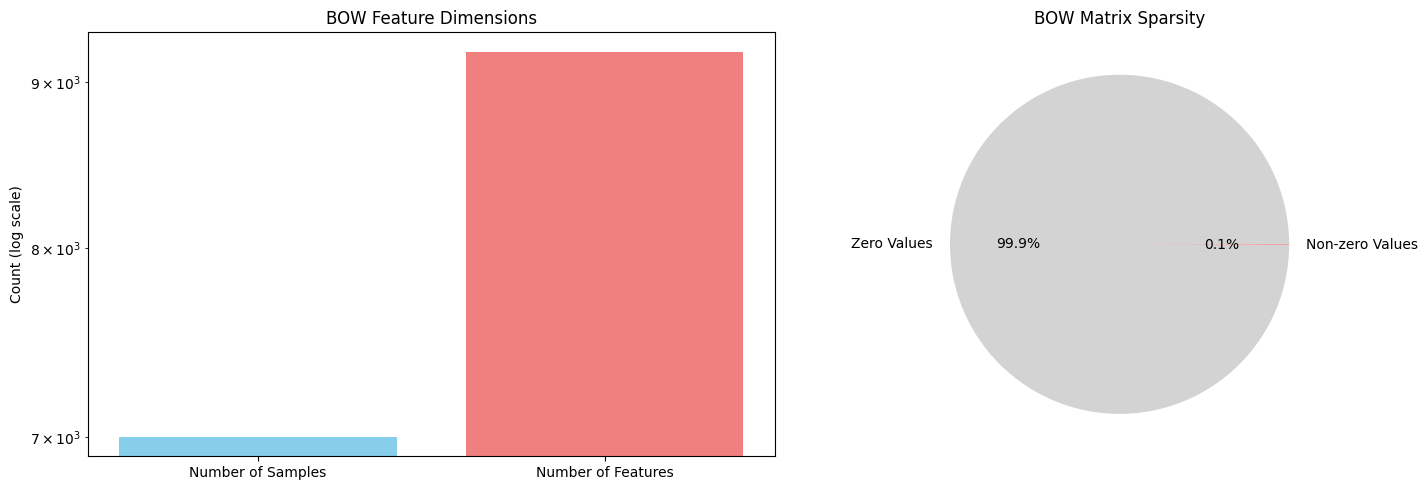

In [ ]:
import seaborn as sns

import matplotlib.pyplot as plt

# Get dimensions of BOW features
n_samples, n_features = X_bow.shape

# Calculate sparsity (percentage of zero values)
sparsity = (X_bow == 0).sum() / (n_samples * n_features) * 100

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Visualize the dimensions
ax1.bar(['Number of Samples', 'Number of Features'], [n_samples, n_features], color=['skyblue', 'lightcoral'])
ax1.set_title('BOW Feature Dimensions')
ax1.set_yscale('log')  # Using log scale due to large difference
ax1.set_ylabel('Count (log scale)')

# Plot 2: Show sparsity
ax2.pie([sparsity, 100-sparsity], labels=['Zero Values', 'Non-zero Values'],
    colors=['lightgray', 'lightcoral'], autopct='%1.1f%%')
ax2.set_title('BOW Matrix Sparsity')

plt.tight_layout()
print(f"Total number of samples: {n_samples:,}")
print(f"Total number of features (vocabulary size): {n_features:,}")
print(f"Matrix sparsity: {sparsity:.2f}%")

## 3.1 Feature Design: Sentiment-Frequency Features

Each tweet becomes a vector of size 3, using the training-set `freqs` dictionary:
- $x_0 = 1$ (bias term)
- $x_1$ = sum of each word's frequency in **positive** training tweets
- $x_2$ = sum of each word's frequency in **negative** training tweets

Words missing from the dictionary contribute 0 (via `dict.get(key, 0)`). The features feed a linear model:
$$
z = \theta_0 x_0 + \theta_1 x_1 + \theta_2 x_2
$$

In [ ]:
def extract_sentiment_features(tweet, freqs):
    """
    Extract sentiment-based features for a single tweet.

    Args:
        tweet (str): The tweet text.
        freqs (dict): Dictionary of word frequencies by sentiment.

    Returns:
        np.ndarray: Feature vector with bias, positive, and negative frequencies.
    """
    words = process_tweet(tweet)
    # Bias + Positive + Negative
    x = np.zeros(3)
    x[0] = 1  # Bias term

    # Loop through each word in the list of words
    for word in words:
        x[1] += freqs.get((word, 1.0), 0)   # how often this word appeared in positive tweets
        x[2] += freqs.get((word, 0.0), 0)   # how often this word appeared in negative tweets

    return x

## 3.2 Modeling with Logistic Regression
The features for all training tweets are stacked into a matrix and used to train a logistic regression model.

In [ ]:
# Extract features for training data
X_sentiment = np.array([extract_sentiment_features(tweet, freqs) for tweet in train_x])

# Train the logistic regression model
model_sentiment = LogisticRegression(max_iter=100)
model_sentiment.fit(X_sentiment, train_y.ravel())

LogisticRegression()

## 3.3 Evaluation
The sentiment-feature model is evaluated on the same test set.

In [ ]:
# Prepare test set features
X_sentiment_test = np.array([extract_sentiment_features(tweet, freqs) for tweet in test_x])

# Evaluate the sentiment-based model
evaluate_model(model_sentiment, X_sentiment_test, test_y)



Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99      1500
         1.0       0.99      1.00      0.99      1500

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000


Jaccard Index or IOU: 0.9855


**Result:** With only 2 features (positive and negative word frequencies), the model reaches a Jaccard of 0.986 (22 errors), almost as good as BoW with 9,197 features. Its weakness is that summing frequencies loses which words appeared, so a few very common positive words can outweigh one strong negative signal.

Total number of samples: 7,000
Total number of features (vocabulary size): 3
Matrix sparsity: 1.32%


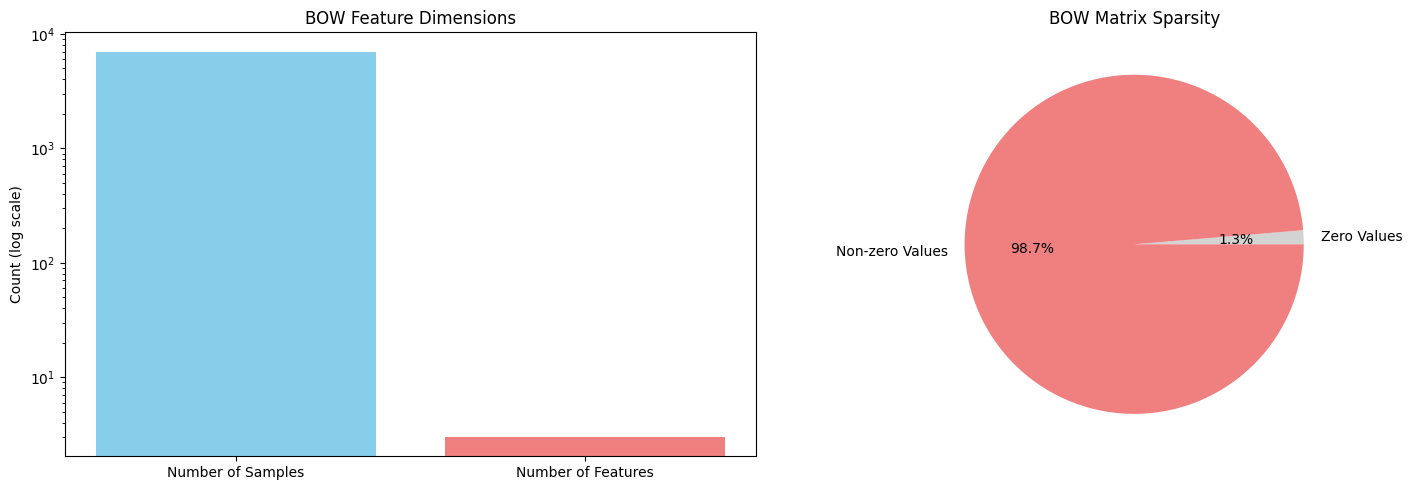

In [ ]:
import seaborn as sns

import matplotlib.pyplot as plt

# Get dimensions of BOW features
n_samples, n_features = X_sentiment.shape

# Calculate sparsity (percentage of zero values)
sparsity = (X_sentiment == 0).sum() / (n_samples * n_features) * 100

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Visualize the dimensions
ax1.bar(['Number of Samples', 'Number of Features'], [n_samples, n_features], color=['skyblue', 'lightcoral'])
ax1.set_title('BOW Feature Dimensions')
ax1.set_yscale('log')  # Using log scale due to large difference
ax1.set_ylabel('Count (log scale)')

# Plot 2: Show sparsity
ax2.pie([sparsity, 100-sparsity], labels=['Zero Values', 'Non-zero Values'],
    colors=['lightgray', 'lightcoral'], autopct='%1.1f%%')
ax2.set_title('BOW Matrix Sparsity')

plt.tight_layout()
print(f"Total number of samples: {n_samples:,}")
print(f"Total number of features (vocabulary size): {n_features:,}")
print(f"Matrix sparsity: {sparsity:.2f}%")

# Part 4: TF-IDF Approach

### 4.1 Feature Design: TF-IDF

TF-IDF re-weights word counts so that words common across all tweets count less and rarer words count more, then scales each tweet's vector to unit length.

Design choices:
- `TfidfVectorizer(tokenizer=process_tweet)`: the same tokenization as Bag-of-Words, so only the weighting differs
- `lowercase=False`: `process_tweet` already lowercases, and lowercasing first would turn `:D` into `:d`
- Fit on the **training tweets only**, then transform the test tweets

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 4.1 TF-IDF features

# Same tokenization as BoW (process_tweet), so only the weighting differs
tfidf_vectorizer = TfidfVectorizer(
    tokenizer=process_tweet,   # clean, tokenize, remove stopwords, stem
    lowercase=False,           # process_tweet already lowercases (keeps :D intact)
    token_pattern=None,        # we use our own tokenizer
)

# Learn vocabulary + IDF from TRAINING tweets only, then apply to test tweets
X_tfidf = tfidf_vectorizer.fit_transform(train_x)
X_tfidf_test = tfidf_vectorizer.transform(test_x)

print("Shape of X_tfidf:     ", X_tfidf.shape)
print("Shape of X_tfidf_test:", X_tfidf_test.shape)
print("Vocabulary size (TF-IDF):", len(tfidf_vectorizer.vocabulary_), "| BoW:", len(vocab_dict))

# ---- Quick look at what TF-IDF learned ----
terms = tfidf_vectorizer.get_feature_names_out()
idf = tfidf_vectorizer.idf_
order = np.argsort(idf)
print("\nMost common words (lowest IDF, down-weighted):")
print([(terms[i], round(idf[i], 2)) for i in order[:8]])
print("Rarest words (highest IDF, up-weighted):")
print([(terms[i], round(idf[i], 2)) for i in order[-5:]])

# TF-IDF weights for one example tweet
row = X_tfidf[1]
print("\nTweet:", train_x[1])
print("TF-IDF weights:", {terms[i]: round(v, 3) for i, v in zip(row.indices, row.data)})

Shape of X_tfidf:      (7000, 9197)
Shape of X_tfidf_test: (3000, 9197)
Vocabulary size (TF-IDF): 9197 | BoW: 9197

Most common words (lowest IDF, down-weighted):
[(':(', np.float64(1.83)), (':)', np.float64(2.08)), (':-)', np.float64(3.72)), (':D', np.float64(3.78)), ('...', np.float64(3.93)), (':-(', np.float64(3.99)), ('thanks', np.float64(4.1)), ('u', np.float64(4.11))]
Rarest words (highest IDF, up-weighted):
[('🚲', np.float64(9.16)), ('\U000fe196', np.float64(9.16)), ('\U000fe334', np.float64(9.16)), ('\U000fec00', np.float64(9.16)), ('--->', np.float64(9.16))]

Tweet: Movie marathon anyonneeee :(((( loner af
TF-IDF weights: {'movie': np.float64(0.365), 'marathon': np.float64(0.466), 'anyonneee': np.float64(0.518), ':(': np.float64(0.103), 'loner': np.float64(0.466), 'af': np.float64(0.393)}


#### Train and evaluate
Logistic regression with the same settings as the Bag-of-Words model, so only the features differ. Metrics: accuracy, precision, recall, F1 and Jaccard (IoU), with Bag-of-Words shown side by side.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, jaccard_score, classification_report

# Train and evaluate the TF-IDF model

# ---- Train: same settings as the BoW model, only the features differ ----
model_tfidf = LogisticRegression(max_iter=1000)
model_tfidf.fit(X_tfidf, train_y.ravel())

# ---- Full report for TF-IDF ----
y_true = test_y.ravel()
y_hat_tfidf = model_tfidf.predict(X_tfidf_test)
print("TF-IDF Classification Report:")
print(classification_report(y_true, y_hat_tfidf, target_names=["Negative (0)", "Positive (1)"], digits=4))

# ---- Side-by-side comparison with BoW ----
def get_metrics(model, X, y):
    y_hat = model.predict(X)
    return {
        "Accuracy":  accuracy_score(y, y_hat),
        "Precision": precision_score(y, y_hat),
        "Recall":    recall_score(y, y_hat),
        "F1":        f1_score(y, y_hat),
        "Jaccard":   jaccard_score(y, y_hat),
        "Errors (of 3000)": int((y_hat != y).sum()),
    }

comparison = pd.DataFrame({
    "BoW":    get_metrics(model_bow, X_bow_test, y_true),
    "TF-IDF": get_metrics(model_tfidf, X_tfidf_test, y_true),
}).T
print("\nBoW vs TF-IDF on the test set:")
print(comparison.round(4))

TF-IDF Classification Report:
              precision    recall  f1-score   support

Negative (0)     0.9973    0.9960    0.9967      1500
Positive (1)     0.9960    0.9973    0.9967      1500

    accuracy                         0.9967      3000
   macro avg     0.9967    0.9967    0.9967      3000
weighted avg     0.9967    0.9967    0.9967      3000


BoW vs TF-IDF on the test set:
        Accuracy  Precision  Recall      F1  Jaccard  Errors (of 3000)
BoW       0.9947     0.9907  0.9987  0.9947   0.9894              16.0
TF-IDF    0.9967     0.9960  0.9973  0.9967   0.9934              10.0


**Result:** TF-IDF is the best model (Jaccard 0.993, 10 errors vs 16 for BoW), and its errors are more balanced between the two classes. The difference is small (6 tweets out of 3,000), so the two are close to tied.

#### Feature importance
The most influential words for positive and negative predictions, taken from the logistic regression weights.

/tmp/ipykernel_970/3044581191.py:22: UserWarning: Glyph 12299 (\N{RIGHT DOUBLE ANGLE BRACKET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 12299 (\N{RIGHT DOUBLE ANGLE BRACKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


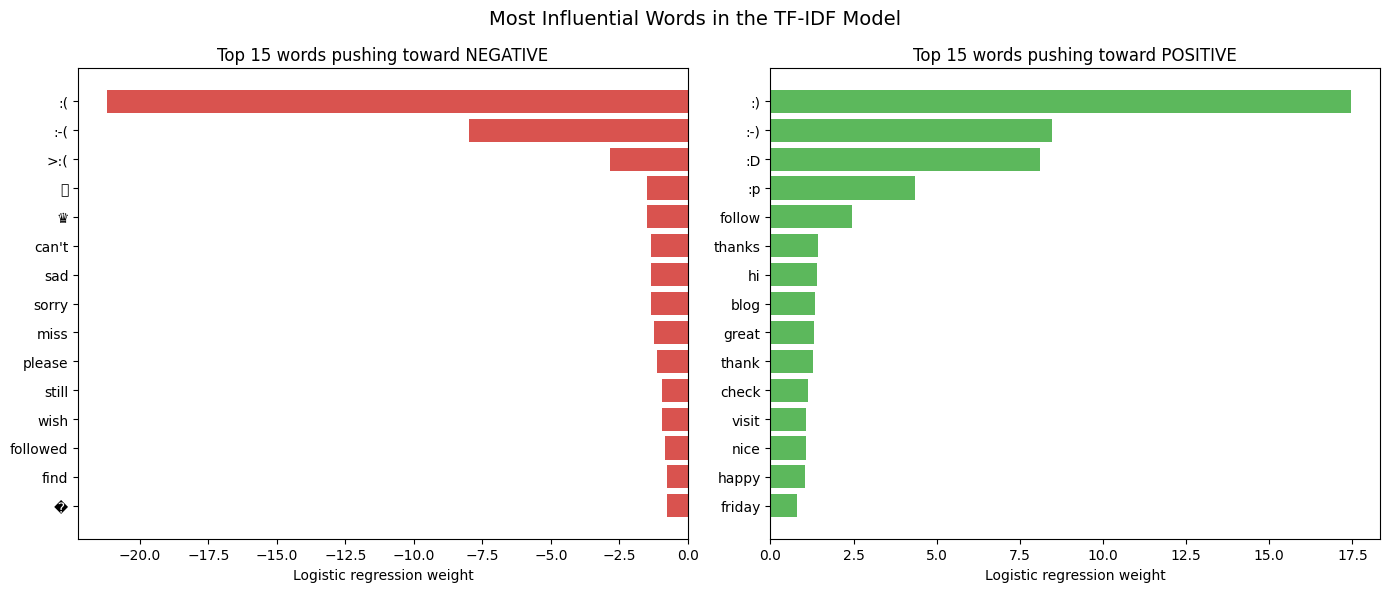

Emoticon weights (rank by influence out of 9197 words):
  :)   weight = +17.457   rank #2
  :(   weight = -21.185   rank #1
  :-)  weight = +8.467   rank #3
  :D   weight = +8.120   rank #4
  :-(  weight = -7.998   rank #5


In [ ]:
import matplotlib.pyplot as plt

# Feature importance from the TF-IDF model

coefs = model_tfidf.coef_.ravel()                    # one learned weight per word
terms = tfidf_vectorizer.get_feature_names_out()     # word for each column
top_n = 15

neg_idx = np.argsort(coefs)[:top_n]                  # most negative weights
pos_idx = np.argsort(coefs)[-top_n:][::-1]           # most positive weights

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh([terms[i] for i in neg_idx][::-1], coefs[neg_idx][::-1], color="#d9534f")
axes[0].set_title(f"Top {top_n} words pushing toward NEGATIVE")
axes[0].set_xlabel("Logistic regression weight")

axes[1].barh([terms[i] for i in pos_idx][::-1], coefs[pos_idx][::-1], color="#5cb85c")
axes[1].set_title(f"Top {top_n} words pushing toward POSITIVE")
axes[1].set_xlabel("Logistic regression weight")

plt.suptitle("Most Influential Words in the TF-IDF Model", fontsize=14)
plt.tight_layout()
plt.show()

# Where do the emoticons rank? (TF-IDF gave them low weights; did the model compensate?)
rank = {i: r + 1 for r, i in enumerate(np.argsort(-np.abs(coefs)))}
vocab_tfidf = tfidf_vectorizer.vocabulary_
print("Emoticon weights (rank by influence out of", len(coefs), "words):")
for emo in [":)", ":(", ":-)", ":D", ":-("]:
    if emo in vocab_tfidf:
        i = vocab_tfidf[emo]
        print(f"  {emo:<4} weight = {coefs[i]:+.3f}   rank #{rank[i]}")

**Observations:**
- The top features on both sides are emoticons, with weights far larger than any real word. The model is mostly an emoticon detector.
- Real sentiment words were also learned (*sad, sorry, miss* vs *thanks, great, happy*).
- Some features reflect dataset quirks, not sentiment. The crown symbol ♛ is strongly negative because one fan posted nearly the same tweet many times, always ending in `:(`, even though it says "I LOVE YOU SO MUCH". Words like *follow, check, blog* lean positive because of friendly promotional tweets.

In [ ]:
crown = "♛"
hits = [(tweet, int(label)) for tweet, label in zip(train_x, train_y.ravel()) if crown in tweet]
print(f"'{crown}' appears in {len(hits)} training tweets "
      f"({sum(l == 0 for _, l in hits)} negative, {sum(l == 1 for _, l in hits)} positive)\n")
for tweet, label in hits[:10]:
    print(f"[{'POS' if label else 'NEG'}] {tweet}")

'♛' appears in 27 training tweets (27 negative, 0 positive)

[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.326
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.347
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.333
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.337
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.340
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber :( x15.324
》》》》ＳＥＥ ＭＥ
♛♛♛
[NEG] ♛♛♛
》》》》 
I LOVE YOU SO MUCH.
I BELİEVE THAT HE WİLL FOLLOW.
PLEASE FOLLOW ME PLEASE JUSTİN @justinbieber

In [ ]:
n_train = sum("♛" in t for t in train_x)
n_test  = sum("♛" in t for t in test_x)
print(f"Crown spam tweets: {n_train} in train, {n_test} in test")

Crown spam tweets: 27 in train, 8 in test


# Part 5: Error Analysis

All three approaches tested on custom tweets covering negation, repetition and sarcasm.

In [ ]:
# Function to test custom tweets and output probabilities
def test_custom_tweets(tweets, model, feature_extraction_func, **kwargs):
    """
    Test logistic regression model on custom tweets and output probabilities.

    Args:
        tweets (list of str): List of tweets to test.
        model (LogisticRegression): Trained logistic regression model.
        feature_extraction_func (function): Function to extract features.
        kwargs: Additional arguments for the feature extraction function.
    """
    for tweet in tweets:
        features = feature_extraction_func(tweet, **kwargs).reshape(1, -1)  # Prepare features
        prob = model.predict_proba(features)[0, 1]  # Positive class probability
        sentiment = 'Positive' if prob >= 0.5 else 'Negative'
        print(f"'{tweet}' -> {sentiment} ({prob:.4f})")

# Example custom tweets
custom_tweets = [
    'I am happy',
    'I am bad',
    'I do not love it but it is not too annoying either',
    'this movie should have been great.',
    'Who made this stupid movie?',
    'great',
    'not good',
    'not too bad',
    'great great',
    'great great great',
    'great great great great'
]

# Convert vocab list to dictionary
vocab_dict = {word: idx for idx, word in enumerate(unique_words)}

# Test with Bag-of-Words model
print("Testing BoW Model:")
test_custom_tweets(custom_tweets, model_bow, extract_bow_features, vocab=vocab_dict)

# Test with Sentiment-based model
print("\nTesting Sentiment-based Model:")
test_custom_tweets(custom_tweets, model_sentiment, extract_sentiment_features, freqs=freqs)

Testing BoW Model:
'I am happy' -> Positive (0.7783)
'I am bad' -> Positive (0.6565)
'I do not love it but it is not too annoying either' -> Positive (0.6939)
'this movie should have been great.' -> Positive (0.7995)
'Who made this stupid movie?' -> Positive (0.7374)
'great' -> Positive (0.8035)
'not good' -> Positive (0.7547)
'not too bad' -> Positive (0.6565)
'great great' -> Positive (0.8641)
'great great great' -> Positive (0.9082)
'great great great great' -> Positive (0.9389)

Testing Sentiment-based Model:
'I am happy' -> Positive (0.8956)
'I am bad' -> Positive (0.6178)
'I do not love it but it is not too annoying either' -> Positive (0.8737)
'this movie should have been great.' -> Positive (0.8953)
'Who made this stupid movie?' -> Positive (0.7769)
'great' -> Positive (0.9012)
'not good' -> Positive (0.8801)
'not too bad' -> Positive (0.6178)
'great great' -> Positive (0.9659)
'great great great' -> Positive (0.9888)
'great great great great' -> Positive (0.9964)


### 5.1 Error Analysis and Comparison

- Collect the misclassified test tweets for each model (Bag-of-Words, sentiment features, TF-IDF)
- Compare errors across models: which tweets fool all three, and which fool only one
- Probe each model's default guess with an empty tweet
- Compare approaches using F1 and Jaccard, then summarize error patterns and possible improvements

In [ ]:
def error_analysis(test_x, test_y, model, feature_extraction_func, **kwargs):
    """
    Perform error analysis by identifying misclassified tweets.

    Args:
        test_x (list of str): Test set tweets.
        test_y (np.ndarray): True labels for the test set.
        model (LogisticRegression): Trained logistic regression model.
        feature_extraction_func (function): Function to extract features.
        kwargs: Additional arguments required by the feature extraction function.
    """
    print("\nError Analysis:")
    for tweet, true_label in zip(test_x, test_y):
        features = feature_extraction_func(tweet, **kwargs)
        features = features.reshape(1, -1)  # Reshape for sklearn compatibility
        pred_label = model.predict(features)[0]
        if pred_label != true_label:
            print(f"Misclassified Tweet: '{tweet}'")
            print(f"True Label: {true_label}, Predicted Label: {pred_label}\n")

# Convert vocab list to dictionary
vocab_dict = {word: idx for idx, word in enumerate(unique_words)}

# Perform error analysis
print("Error Analysis for BoW Model:")
error_analysis(test_x, test_y, model_bow, extract_bow_features, vocab=vocab_dict)

print("\nError Analysis for Sentiment-based Model:")
error_analysis(test_x, test_y, model_sentiment, extract_sentiment_features, freqs=freqs)

# Error analysis for the TF-IDF model

# Wrapper so TF-IDF matches the interface of the other two feature functions
def extract_tfidf_features(tweet, vectorizer):
    return vectorizer.transform([tweet]).toarray().ravel()

print("\nError Analysis for TF-IDF Model:")
error_analysis(test_x, test_y, model_tfidf, extract_tfidf_features, vectorizer=tfidf_vectorizer)

# Custom tweets for TF-IDF too, so all three models are compared on the same examples
print("\nTesting TF-IDF Model:")
test_custom_tweets(custom_tweets, model_tfidf, extract_tfidf_features, vectorizer=tfidf_vectorizer)

Error Analysis for BoW Model:

Error Analysis:
Misclassified Tweet: 'Zehr khany ka time is coming soon.....: ('
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: 'Sr. Financial Analyst - Expedia, Inc.: (#Bellevue, WA) http://t.co/ktknMhvwCI #Finance #ExpediaJobs #Job #Jobs #Hiring'
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: '@bae_ts WHATEVER STIL L YOUNG &gt;:-('
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: 'Screenshots from http://t.co/U2RdUgq6wH there's a competition open to meet ariana grande some countries excluded :( http://t.co/OdI14ms8NR'
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: '@PSYCRM you still haven't ! ! : ('
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: '@JindalDaily praying for you all. So sorry this happened : ('
True Label: [0.], Predicted Label: 1.0

Misclassified Tweet: '@OTRJSJ offers you my mixtape. will you talk to me more now : ( suckmejimin.'
True Label: [0.], Predicted Label: 1.0

Mi

In [ ]:
# ---- Compare errors across all three models ----
def misclassified(model, X):
    return set(np.where(model.predict(X) != test_y.ravel())[0])

X_sent_test = np.array([extract_sentiment_features(t, freqs) for t in test_x])
errors = {
    "BoW":       misclassified(model_bow, X_bow_test),
    "Sentiment": misclassified(model_sentiment, X_sent_test),
    "TF-IDF":    misclassified(model_tfidf, X_tfidf_test),
}
for name, idx in errors.items():
    print(f"{name:<10} {len(idx):>3} errors  (Jaccard: {jaccard_score(test_y.ravel(), np.isin(np.arange(len(test_y)), list(idx)) ^ (test_y.ravel() == 1)):.4f})")

common = errors["BoW"] & errors["Sentiment"] & errors["TF-IDF"]
print(f"\nMisclassified by ALL three models: {len(common)}")
for i in sorted(common):
    print(f"  [true: {'POS' if test_y[i, 0] == 1 else 'NEG'}] {test_x[i]}")

only_sent = errors["Sentiment"] - errors["BoW"] - errors["TF-IDF"]
print(f"\nMisclassified ONLY by the Sentiment model: {len(only_sent)}")

# ---- Each model's default guess: a tweet with no known words ----
print("\nDefault guess (empty tweet) -> probability of Positive:")
print(f"  BoW:       {model_bow.predict_proba(extract_bow_features('', vocab_dict).reshape(1, -1))[0, 1]:.3f}")
print(f"  Sentiment: {model_sentiment.predict_proba(extract_sentiment_features('', freqs).reshape(1, -1))[0, 1]:.3f}")
print(f"  TF-IDF:    {model_tfidf.predict_proba(extract_tfidf_features('', tfidf_vectorizer).reshape(1, -1))[0, 1]:.3f}")

BoW         16 errors  (Jaccard: 0.9894)
Sentiment   22 errors  (Jaccard: 0.9855)
TF-IDF      10 errors  (Jaccard: 0.9934)

Misclassified by ALL three models: 8
  [true: NEG] Sr. Financial Analyst - Expedia, Inc.: (#Bellevue, WA) http://t.co/ktknMhvwCI #Finance #ExpediaJobs #Job #Jobs #Hiring
  [true: NEG] Screenshots from http://t.co/U2RdUgq6wH there's a competition open to meet ariana grande some countries excluded :( http://t.co/OdI14ms8NR
  [true: NEG] @OTRJSJ offers you my mixtape. will you talk to me more now : ( suckmejimin.
  [true: POS] @ellekagaoan @chinmarquez Catch up once in a while :( &gt;:D&lt; @aditriphosphate @ErinMonzon
  [true: NEG] @phenomyoutube u probs had more fun with david than me : (
  [true: NEG] @Skulker_PoA @ASUS_ROG Hi Skulker, check this thread: https://t.co/vMlI793G25 PG279Q isn’t coming anything soon sadly :(
  [true: POS] Remember that one time I didn't go to flume/kaytranada/alunageorge even though I had tickets? I still want to kms. : ) : )
  [true: 

### Findings

| Approach | F1 | Jaccard | Errors |
|---|---|---|---|
| BoW | 0.9947 | 0.9894 | 16 |
| Sentiment | 0.9927 | 0.9855 | 22 |
| TF-IDF | 0.9967 | 0.9934 | 10 |

**Strengths and weaknesses**
- **BoW:** simple and interpretable, but very high-dimensional and sparse, and repeating a word keeps raising confidence.
- **Sentiment:** only 2 features and nearly as accurate, but it loses which words appeared.
- **TF-IDF:** best scores, and normalization removes the repetition effect ("great" and "great great great great" get the same score), but it still ignores word order.

**Error patterns**
- **Unusual emoticons:** most errors contain `: (` with a space or variants like `(:(`, which the tokenizer doesn't recognize, so the model loses its strongest clue.
- **Default positive guess:** with no known words, BoW and Sentiment predict 72–75% positive, so tweets like "Who made this stupid movie?" are called positive.
- **Wrong labels:** some "errors" are mislabeled tweets, e.g. a job posting labeled negative, or a tweet about wanting to "kms" labeled positive because of `: )`.
- **Negation:** `process_tweet` removes "not" as a stopword, so "not good" becomes "good" in every model.

**Improvements**
- Keep negation words, or use word pairs (bigrams) like "not good".
- Normalize emoticon variants before tokenizing.
- Remove duplicate and mislabeled tweets.
- Use context-aware models (embeddings or transformers) for sarcasm and phrases.